--- 1. KẾT QUẢ SÁT HẠCH 5-FOLD CV (ĐIỂM TRUNG BÌNH) ---
Accuracy    : 82.83%
Precision   : 81.34%
Recall      : 82.01%
F1-Score    : 81.38%
ROC-AUC     : 90.92%
Brier Score : 0.1240 (Càng gần 0 càng tốt)

--- 2. KHOẢNG TIN CẬY 95% CI ---
95% CI Precision : [67.74% - 93.75%]
95% CI Recall    : [83.33% - 100.00%]
95% CI F1-Score  : [76.92% - 95.08%]
95% CI ROC-AUC   : [88.68% - 99.45%]
95% CI Brier     : [0.0580 - 0.1560]

--- 3. ĐANG VẼ VÀ LƯU 5 BIỂU ĐỒ ---


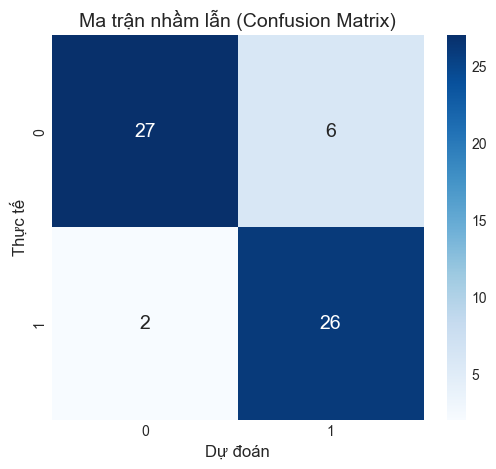

<Figure size 700x600 with 0 Axes>

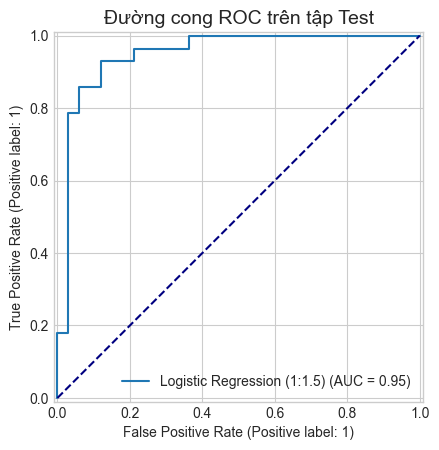

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_14380\1216361404.py:120: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Coef', y='Feature', data=coef_df, palette='viridis')


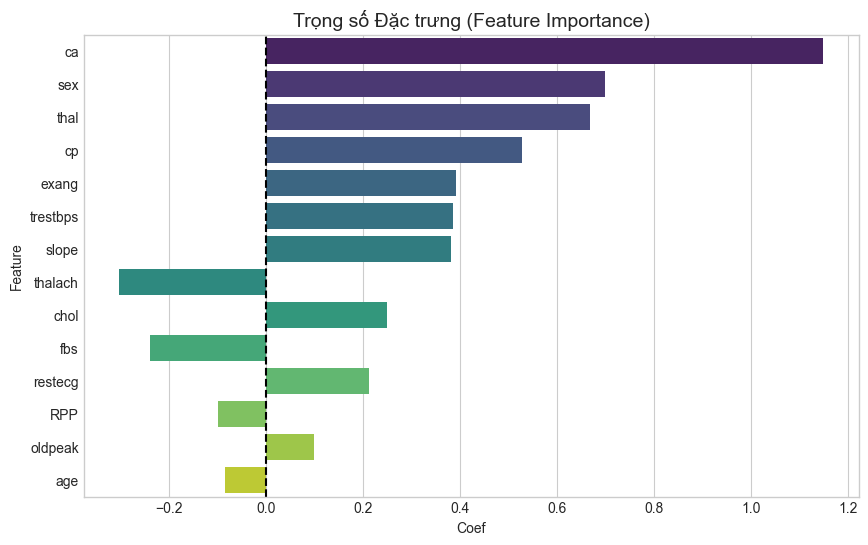

<Figure size 700x600 with 0 Axes>

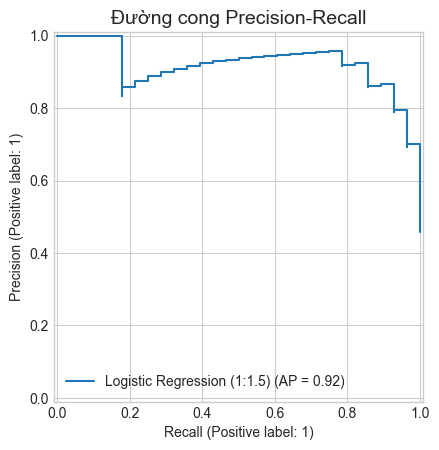

<Figure size 700x600 with 0 Axes>

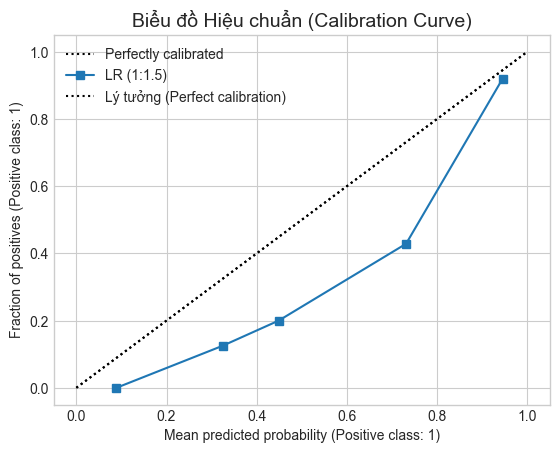

In [9]:
import ssl
ssl._create_default_https_context = ssl._create_unverified_context
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.utils import resample
from sklearn.metrics import (accuracy_score, recall_score, roc_auc_score, 
                             precision_score, f1_score, brier_score_loss,
                             confusion_matrix, RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.calibration import CalibrationDisplay

# ==========================================
# 0. TẢI VÀ XỬ LÝ DỮ LIỆU THÔ
# ==========================================
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
names = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg',
         'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']
df = pd.read_csv(url, names=names, na_values='?')

# Xử lý missing value và tạo biến y sinh RPP
imputer = SimpleImputer(strategy='median')
df_imputed = pd.DataFrame(imputer.fit_transform(df), columns=df.columns)
df_imputed['RPP'] = df_imputed['trestbps'] * df_imputed['thalach']

X = df_imputed.drop('target', axis=1)
y = (df_imputed['target'] > 0).astype(int)

# Khởi tạo Pipeline với trọng số thiên vị lâm sàng (1:1.5)
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression(max_iter=1000, class_weight={0: 1, 1: 1.5}))
])

# ==========================================
# 1. ĐÁNH GIÁ CỐT LÕI BẰNG 5-FOLD CV
# ==========================================
cv_5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {'acc': 'accuracy', 'prec': 'precision', 'recall': 'recall', 
           'f1': 'f1', 'auc': 'roc_auc', 'brier': 'neg_brier_score'}
cv_results = cross_validate(pipeline, X, y, cv=cv_5, scoring=scoring)

print("--- 1. KẾT QUẢ SÁT HẠCH 5-FOLD CV (ĐIỂM TRUNG BÌNH) ---")
print(f"Accuracy    : {cv_results['test_acc'].mean():.2%}")
print(f"Precision   : {cv_results['test_prec'].mean():.2%}")
print(f"Recall      : {cv_results['test_recall'].mean():.2%}")
print(f"F1-Score    : {cv_results['test_f1'].mean():.2%}")
print(f"ROC-AUC     : {cv_results['test_auc'].mean():.2%}")
print(f"Brier Score : {abs(cv_results['test_brier'].mean()):.4f} (Càng gần 0 càng tốt)\n")

# ==========================================
# 2. TÍNH KHOẢNG TIN CẬY 95% (BOOTSTRAPPING 1000 VÒNG)
# ==========================================
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
pipeline.fit(X_train, y_train)

n_iterations = 1000
rec_scores, auc_scores, prec_scores, f1_scores, brier_scores = [], [], [], [], []

for i in range(n_iterations):
    X_bs, y_bs = resample(X_test, y_test)
    if len(np.unique(y_bs)) < 2: continue
        
    y_pred = pipeline.predict(X_bs)
    y_prob = pipeline.predict_proba(X_bs)[:, 1]
    
    rec_scores.append(recall_score(y_bs, y_pred))
    auc_scores.append(roc_auc_score(y_bs, y_prob))
    prec_scores.append(precision_score(y_bs, y_pred, zero_division=0))
    f1_scores.append(f1_score(y_bs, y_pred))
    brier_scores.append(brier_score_loss(y_bs, y_prob))

def get_95_ci(scores):
    return np.percentile(scores, 2.5), np.percentile(scores, 97.5)

print("--- 2. KHOẢNG TIN CẬY 95% CI ---")
print(f"95% CI Precision : [{get_95_ci(prec_scores)[0]:.2%} - {get_95_ci(prec_scores)[1]:.2%}]")
print(f"95% CI Recall    : [{get_95_ci(rec_scores)[0]:.2%} - {get_95_ci(rec_scores)[1]:.2%}]")
print(f"95% CI F1-Score  : [{get_95_ci(f1_scores)[0]:.2%} - {get_95_ci(f1_scores)[1]:.2%}]")
print(f"95% CI ROC-AUC   : [{get_95_ci(auc_scores)[0]:.2%} - {get_95_ci(auc_scores)[1]:.2%}]")
print(f"95% CI Brier     : [{get_95_ci(brier_scores)[0]:.4f} - {get_95_ci(brier_scores)[1]:.4f}]\n")

# ==========================================
# 3. TRỰC QUAN HÓA BÁO CÁO (5 BIỂU ĐỒ CHUẨN)
# ==========================================
print("--- 3. ĐANG VẼ VÀ LƯU 5 BIỂU ĐỒ ---")
plt.style.use('seaborn-v0_8-whitegrid')

# Hình 1: Ma trận nhầm lẫn
y_pred_test = pipeline.predict(X_test)
cm = confusion_matrix(y_test, y_pred_test)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', annot_kws={"size": 14})
plt.title('Ma trận nhầm lẫn (Confusion Matrix)', fontsize=14)
plt.ylabel('Thực tế', fontsize=12)
plt.xlabel('Dự đoán', fontsize=12)
plt.savefig('confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

# Hình 2: Đường cong ROC
plt.figure(figsize=(7,6))
RocCurveDisplay.from_estimator(pipeline, X_test, y_test, name='Logistic Regression (1:1.5)')
plt.plot([0, 1], [0, 1], linestyle='--', color='navy', label='Random Guess')
plt.title('Đường cong ROC trên tập Test', fontsize=14)
plt.savefig('roc_curve.png', dpi=300, bbox_inches='tight')
plt.show()

# Hình 3: Mức độ đóng góp của các đặc trưng (Feature Importance)
coefficients = pipeline.named_steps['lr'].coef_[0]
coef_df = pd.DataFrame({'Feature': X.columns, 'Coef': coefficients})
coef_df['Abs_Coef'] = coef_df['Coef'].abs()
coef_df = coef_df.sort_values(by='Abs_Coef', ascending=False)
plt.figure(figsize=(10,6))
sns.barplot(x='Coef', y='Feature', data=coef_df, palette='viridis')
plt.title('Trọng số Đặc trưng (Feature Importance)', fontsize=14)
plt.axvline(x=0, color='black', linestyle='--')
plt.savefig('feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()

# Hình 4: Đường cong Precision-Recall
plt.figure(figsize=(7,6))
PrecisionRecallDisplay.from_estimator(pipeline, X_test, y_test, name='Logistic Regression (1:1.5)')
plt.title('Đường cong Precision-Recall', fontsize=14)
plt.savefig('pr_curve.png', dpi=300, bbox_inches='tight')
plt.show()

# Hình 5: Biểu đồ Hiệu chuẩn (Calibration Curve)
plt.figure(figsize=(7,6))
CalibrationDisplay.from_estimator(pipeline, X_test, y_test, n_bins=5, name='LR (1:1.5)')
plt.plot([0, 1], [0, 1], "k:", label="Lý tưởng (Perfect calibration)")
plt.legend()
plt.title('Biểu đồ Hiệu chuẩn (Calibration Curve)', fontsize=14)
plt.savefig('calibration_curve.png', dpi=300, bbox_inches='tight')
plt.show()